# 02 — Four tonsils Leiden vs cell type

Same lean resolution sweep as notebook 01, on preprocessed **merged** Tonsil1–4
objects for the RNA ∩ H3K27ac ∩ H3K27me3 overlap (**4,049** cells). Main-paper
**Figure 3**.

- RNA: `X_pca`; chromatin: `X_spectral_harmony` (unchanged)
- Neighbor graphs recomputed on the overlap
- Leiden resolutions **0.25–3.0** (step 0.25)
- Labels: `CellType`

**Figure panels below are drawn from the frozen table** bundled as
`paper_results/four_tonsils_celltype_leiden_resolution.csv`, which matches the
manuscript curves. Neighbor-graph construction and Leiden clustering are
intrinsically stochastic: even with a fixed random seed, a full recompute can
change cluster counts and agreement metrics slightly. That is expected and does
not indicate an error in the analysis. An optional regenerate snippet is
included at the end (commented out) for transparency.

Plots are shown inline only.


In [5]:
%matplotlib inline
import sys
import warnings
from pathlib import Path

warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", UserWarning)

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PACKAGE = Path("/mnt/data1/divyanshu/treseq/tonsils/codes/treseq_paper")
if str(PACKAGE.parent) not in sys.path:
    sys.path.insert(0, str(PACKAGE.parent))

from treseq_paper import config
import importlib
importlib.reload(config)
from treseq_paper.load_resolution import plot_resolution_sweep

sns.set_theme("talk", style="ticks")
plt.rcParams["figure.dpi"] = 120

TABLE = config.FOUR_TONSILS_LEIDEN_VS_CELLTYPE_CSV
if not TABLE.is_file():
    raise FileNotFoundError(TABLE)


## Frozen table (matches the manuscript figure)


In [6]:
vs = pd.read_csv(TABLE)
leiden = vs.query("algorithm == 'leiden'").copy()
if set(leiden["modality"]) != set(config.MODALITIES):
    raise RuntimeError(f"unexpected modalities: {sorted(leiden['modality'].unique())}")
print(f"loaded {TABLE.name}: {len(leiden)} Leiden rows")
display(leiden.round(4))


loaded four_tonsils_celltype_leiden_resolution.csv: 36 Leiden rows


,algorithm,modality,clustering,param,n_clusters,n_types,ARI,NMI,AMI,H_celltype_given_clusters,H_clusters_given_celltype,homogeneity_clusters_given_celltype,completeness_clusters_given_celltype
0,leiden,RNA,RNA,0.25,6,15,0.4417,0.6885,0.6870,1.5804,0.1366,0.5456,0.9328
1,leiden,H3K27ac,H3K27ac,0.25,4,15,0.2944,0.4048,0.4030,2.4122,0.7226,0.3064,0.5960
2,leiden,H3K27me3,H3K27me3,0.25,5,15,0.2377,0.3818,0.3794,2.4716,0.7869,0.2894,0.5612
3,leiden,RNA,RNA,0.50,10,15,0.5005,0.7195,0.7173,1.3051,0.3894,0.6248,0.8480
4,leiden,H3K27ac,H3K27ac,0.50,5,15,0.2635,0.3819,0.3796,2.3954,1.1094,0.3113,0.4939
5,leiden,H3K27me3,H3K27me3,0.50,7,15,0.2057,0.3622,0.3589,2.4029,1.3827,0.3091,0.4374
6,leiden,RNA,RNA,0.75,14,15,0.5525,0.7161,0.7133,1.0231,0.9237,0.7058,0.7266
7,leiden,H3K27ac,H3K27ac,0.75,7,15,0.2737,0.3653,0.3621,2.3717,1.4726,0.3181,0.4290
8,leiden,H3K27me3,H3K27me3,0.75,12,15,0.1956,0.3648,0.3595,2.2243,2.1423,0.3605,0.3692
9,leiden,RNA,RNA,1.00,14,15,0.5612,0.7187,0.7159,1.0098,0.9227,0.7097,0.7279


## Resolution-sweep figure


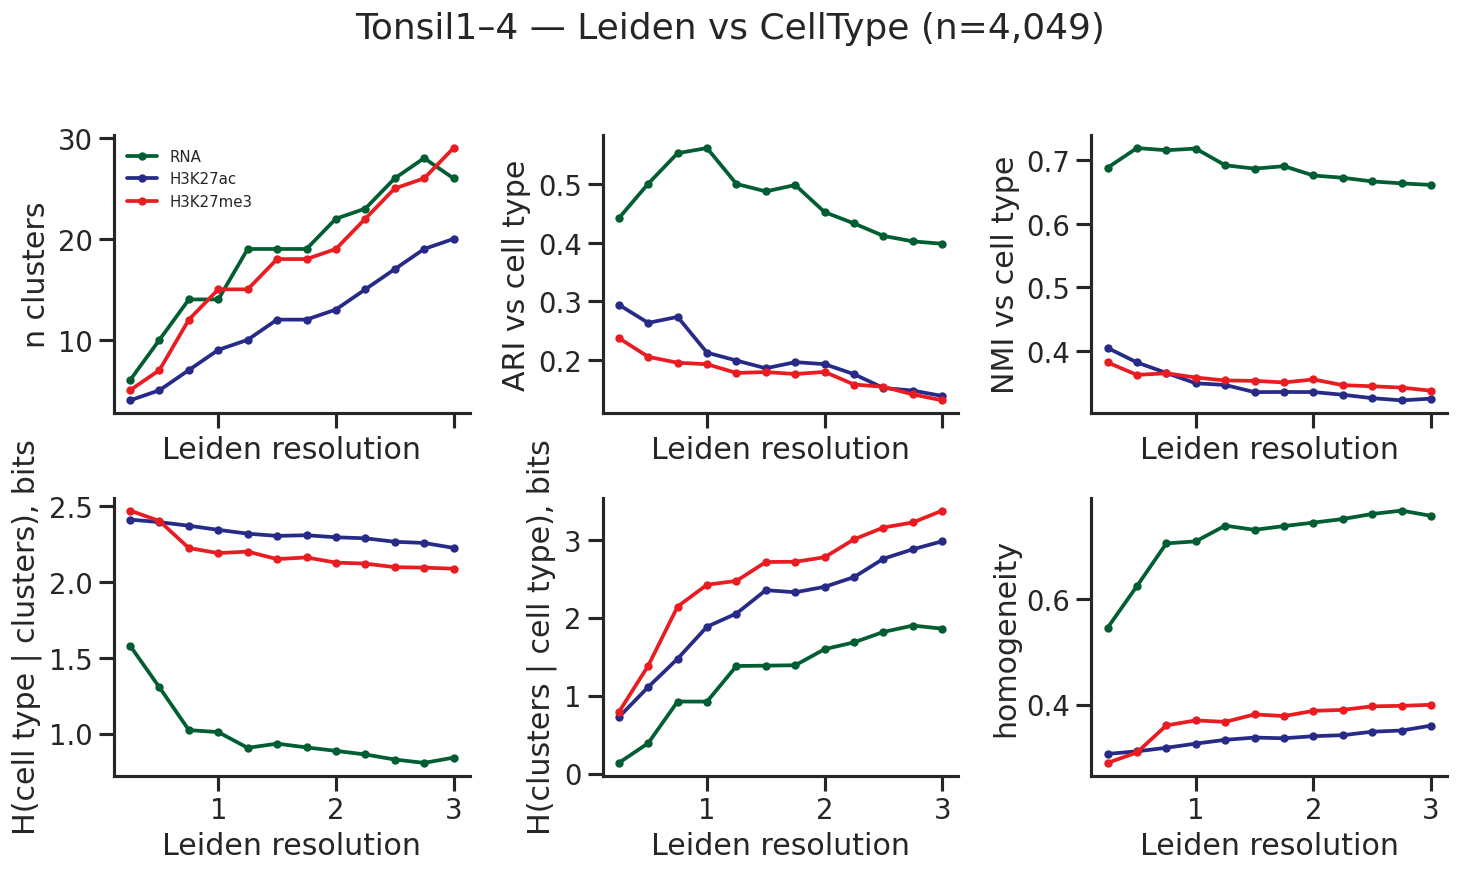

In [7]:
fig, axes = plot_resolution_sweep(
    vs,
    title="Tonsil1–4 — Leiden vs CellType (n=4,049)",
)
plt.show()
# fig.savefig("four_tonsils_celltype_leiden_resolution.pdf", bbox_inches="tight")  # disabled


## Optional: regenerate the table (commented out)

Uncomment the cell below only if you want to recompute Leiden from the
preprocessed objects. Results will be close to the frozen table but are **not
guaranteed to match it bit-for-bit**: nearest-neighbor graphs and Leiden
partitions retain mild run-to-run variability even with `random_state=42`.
Use the frozen table above for manuscript-identical curves.


In [8]:
# from treseq_paper.load_resolution import banner, leiden_vs_celltype, load_four_tonsils
#
# bundle = load_four_tonsils()
# banner(bundle)
# display(pd.Series(bundle["celltype_counts"], name="n_cells").sort_values(ascending=False).to_frame())
# if bundle.get("sample_counts"):
#     display(pd.Series(bundle["sample_counts"], name="n_cells").to_frame())
#
# print("Leiden vs CellType (recompute; may differ mildly from the frozen table) …", flush=True)
# vs_recomputed, labels_by_res = leiden_vs_celltype(bundle)
# display(vs_recomputed.round(4))
#
# fig, axes = plot_resolution_sweep(
#     vs_recomputed,
#     title="Tonsil1–4 — Leiden vs CellType (recomputed)",
# )
# plt.show()
